In [1]:
import csv
number_of_columns = 7
header_row = 0

def import_pv_data(filename, header_row):
    
    batt_data_dict = {}
    with open(filename, "r", newline='') as datafile:
        batt_data = csv.reader(datafile, delimiter=',', quotechar='\"')
        index = 0
        headers = []
        unix_timestamps = []
        for row in batt_data:
            if len(headers) > 0 and len(row) == number_of_columns:
                for c in range (0, number_of_columns):
                    if headers[c] in batt_data_dict:
                        batt_data_dict[headers[c]].append(row[c])
                    else:
                        batt_data_dict[headers[c]] = [row[c]]
            if index == header_row:
                headers = row
            index += 1
    trimmed_dict = {}
    for key in batt_data_dict.keys():
        trimmed_key = key[22:]
        print(trimmed_key)
        trimmed_dict[trimmed_key] = batt_data_dict[key]
    
    return trimmed_dict

datafile = "C:\\Users\\bmirletz\\source\\repos\\sam_dev\\SAM-analyses\\2025\\battwatts_sensitivity\\plots\\aug_31_amy_data.csv"
amy_data = import_pv_data(datafile, header_row)

datafile = "C:\\Users\\bmirletz\\source\\repos\\sam_dev\\SAM-analyses\\2025\\battwatts_sensitivity\\plots\\aug_31_tmy_data.csv"
tmy_data = import_pv_data(datafile, header_row)


1
Power produced without the battery or curtailment (kW)
Weather file ambient temperature (C)
Lifetime electricity load (kW)
Electricity to load from system AC (kW)
Electricity to load from battery AC (kW)
Battery state of charge (%)
1
Lifetime electricity load (kW)
Power produced without the battery or curtailment (kW)
Weather file ambient temperature (C)
Electricity to load from system AC (kW)
Electricity to load from battery AC (kW)
Battery state of charge (%)


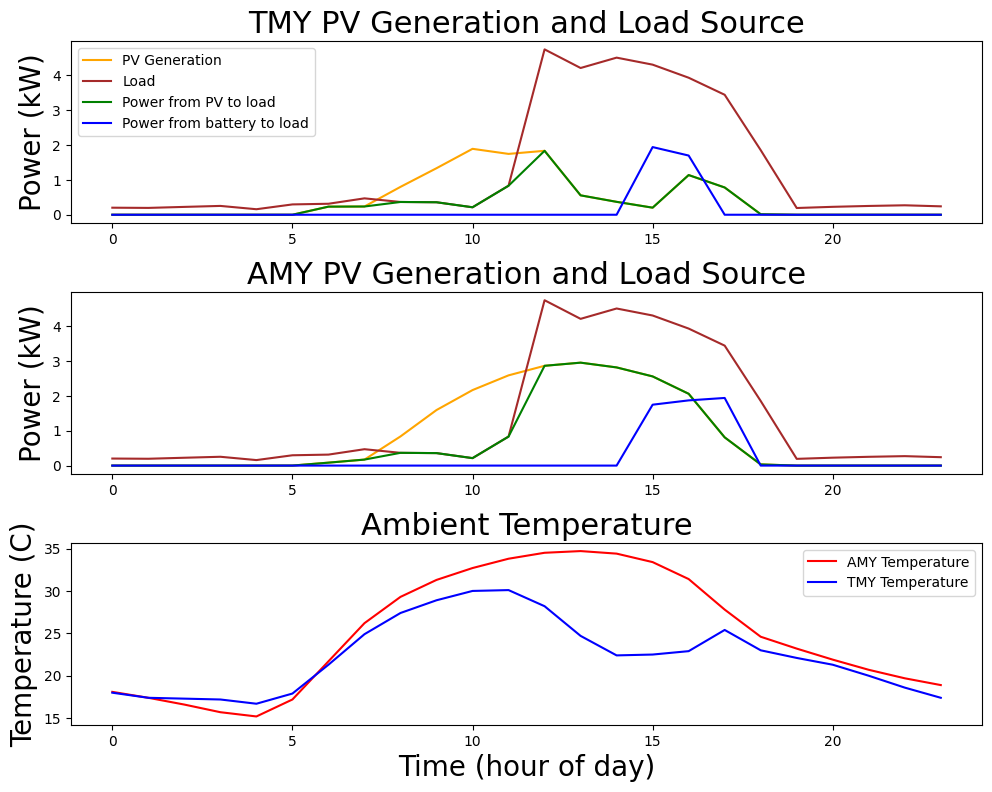

In [16]:
import matplotlib.pyplot as plt
import numpy as np

SMALL_SIZE = 10
MEDIUM_SIZE = 20
BIGGER_SIZE = 22

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

start_time = 24
end_time = start_time + 24
time = np.array(amy_data["1"][start_time:end_time], 'f')
time = time - time[0]
pv_power_amy = np.array(amy_data["Power produced without the battery or curtailment (kW)"][start_time:end_time], 'f')
ambient_temp_amy = np.array(amy_data["Weather file ambient temperature (C)"][start_time:end_time], 'f')
load_amy = np.array(amy_data["Lifetime electricity load (kW)"][start_time:end_time], 'f')
pv_to_load_amy = np.array(amy_data["Electricity to load from system AC (kW)"][start_time:end_time], 'f')
batt_to_load_amy = np.array(amy_data["Electricity to load from battery AC (kW)"][start_time:end_time], 'f')
batt_soc_amy = np.array(amy_data["Battery state of charge (%)"][start_time:end_time], 'f')

pv_power_tmy = np.array(tmy_data["Power produced without the battery or curtailment (kW)"][start_time:end_time], 'f')
ambient_temp_tmy = np.array(tmy_data["Weather file ambient temperature (C)"][start_time:end_time], 'f')
load_tmy = np.array(tmy_data["Lifetime electricity load (kW)"][start_time:end_time], 'f')
pv_to_load_tmy = np.array(tmy_data["Electricity to load from system AC (kW)"][start_time:end_time], 'f')
batt_to_load_tmy = np.array(tmy_data["Electricity to load from battery AC (kW)"][start_time:end_time], 'f')
batt_soc_tmy = np.array(tmy_data["Battery state of charge (%)"][start_time:end_time], 'f')

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8))    
ax1.set_title('TMY PV Generation and Load Source')
ax1.set_ylabel('Power (kW)')
ax2.set_title('AMY PV Generation and Load Source')
ax2.set_ylabel('Power (kW)')

dummy = ax1.plot(time, pv_power_tmy, label="PV Generation", color="orange")
dummy = ax1.plot(time, load_tmy, label="Load", color="brown")
dummy = ax1.plot(time, pv_to_load_tmy, label="Power from PV to load", color="green")
dummy = ax1.plot(time, batt_to_load_tmy, label="Power from battery to load", color="blue")
label = True

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles, labels)

dummy = ax2.plot(time, pv_power_amy, label="PV Generation", color="orange")
dummy = ax2.plot(time, load_amy, label="Load", color="brown")
dummy = ax2.plot(time, pv_to_load_amy, label="Power from PV to load", color="green")
dummy = ax2.plot(time, batt_to_load_amy, label="Power from battery to load", color="blue")
label = True

ax3.set_title('Ambient Temperature')
ax3.set_ylabel('Temperature (C)')
ax3.set_xlabel('Time (hour of day)')
dummy = ax3.plot(time, ambient_temp_amy, label="AMY Temperature", color="red")
dummy = ax3.plot(time, ambient_temp_tmy, label="TMY Temperature", color="blue")
handles, labels = ax3.get_legend_handles_labels()
ax3.legend(handles, labels)

fig.tight_layout(pad=1.0)
fig.savefig("tmy_amy_comparison.png")

In [12]:
print(sum(pv_to_load_amy) + sum(batt_to_load_amy))
print(sum(pv_to_load_tmy) + sum(batt_to_load_tmy))

21.67241
10.772075
